# PDFT Calculation for H$_6$ linear chain

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

In [2]:
# define geometry
mol = fgto.M(atom=f"""
    H -2.5 0 0
    H -1.5 0 0
    H -0.5 0 0
    H 0.5 0 0
    H 1.5 0 0
    H 2.5 0 0
""", unit='bohr', basis='cc-pvtz',
    fragments={i:[i] for i in range(6)},  # atom indices (1-based) of each fragment
    ensembles={'spin': list(range(6))})  # spin ensemble on fragments 1 and 2

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -2.77997089


---
## Do PDFT Calculations

### Inversion Method

In [3]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=50, frag_symm='auto')
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

frag_symm: 2 operations; fragments solved: [0, 1, 2] of 6
P-DFT method=inversion xc=PBE fxc=PBE nao=84 grid=211056


/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/scipy/optimize/_trustregion.py:224: ComplexWarning: Casting complex values to real discards the imaginary part
  p, hits_boundary = m.solve(trust_radius)


  it    1  Ef =    -2.9981524463  dEf =         nan  |dVp| = 2.775e+00
  it    2  Ef =    -2.8402104059  dEf =   1.579e-01  |dVp| = 1.337e+00
  it    3  Ef =    -2.7173388242  dEf =   1.229e-01  |dVp| = 7.168e-01
  it    4  Ef =    -2.6446350024  dEf =   7.270e-02  |dVp| = 4.384e-01
  it    5  Ef =    -2.6035164651  dEf =   4.112e-02  |dVp| = 2.917e-01
  it    6  Ef =    -2.5787228547  dEf =   2.479e-02  |dVp| = 2.124e-01
  it    7  Ef =    -2.5634544777  dEf =   1.527e-02  |dVp| = 1.677e-01
  it    8  Ef =    -2.5536413226  dEf =   9.813e-03  |dVp| = 1.413e-01
  it    9  Ef =    -2.5471139301  dEf =   6.527e-03  |dVp| = 1.253e-01
  it   10  Ef =    -2.5426045951  dEf =   4.509e-03  |dVp| = 1.146e-01
  it   11  Ef =    -2.5393519211  dEf =   3.253e-03  |dVp| = 1.073e-01
  it   12  Ef =    -2.5369108076  dEf =   2.441e-03  |dVp| = 1.021e-01
  it   13  Ef =    -2.5350063612  dEf =   1.904e-03  |dVp| = 9.825e-02
  it   14  Ef =    -2.5334651634  dEf =   1.541e-03  |dVp| = 9.526e-02
  it  

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 50 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


Energy difference (Ha): 3.459e-04, Density error: 1.662e-01


### Reference Method

In [4]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=60, frag_symm='auto')
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

frag_symm: 2 operations; fragments solved: [0, 1, 2] of 6
P-DFT method=reference xc=PBE fxc=PBE nao=84 grid=211056
  it    1  Ef =    -2.9981524463  dEf =         nan  |dVp| = 4.539e-01  L1 = 2.277e+00
  it    2  Ef =    -2.7058132160  dEf =   2.923e-01  |dVp| = 6.361e-02  L1 = 8.902e-01
  it    3  Ef =    -2.6979939909  dEf =   7.819e-03  |dVp| = 4.615e-02  L1 = 8.045e-01
  it    4  Ef =    -2.6915933387  dEf =   6.401e-03  |dVp| = 3.747e-02  L1 = 7.488e-01
  it    5  Ef =    -2.6865738163  dEf =   5.020e-03  |dVp| = 3.248e-02  L1 = 7.091e-01
  it    6  Ef =    -2.6825908993  dEf =   3.983e-03  |dVp| = 2.924e-02  L1 = 6.783e-01
  it    7  Ef =    -2.6793625352  dEf =   3.228e-03  |dVp| = 2.692e-02  L1 = 6.531e-01
  it    8  Ef =    -2.6766854696  dEf =   2.677e-03  |dVp| = 2.511e-02  L1 = 6.315e-01
  it    9  Ef =    -2.6744160252  dEf =   2.269e-03  |dVp| = 2.362e-02  L1 = 6.126e-01
  it   10  Ef =    -2.6724521852  dEf =   1.964e-03  |dVp| = 2.234e-02  L1 = 5.958e-01
  it   11  Ef =

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 60 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


Energy difference (Ha): 4.119e-02, Density error: 3.328e-01


---
## Plot densities and partition potential

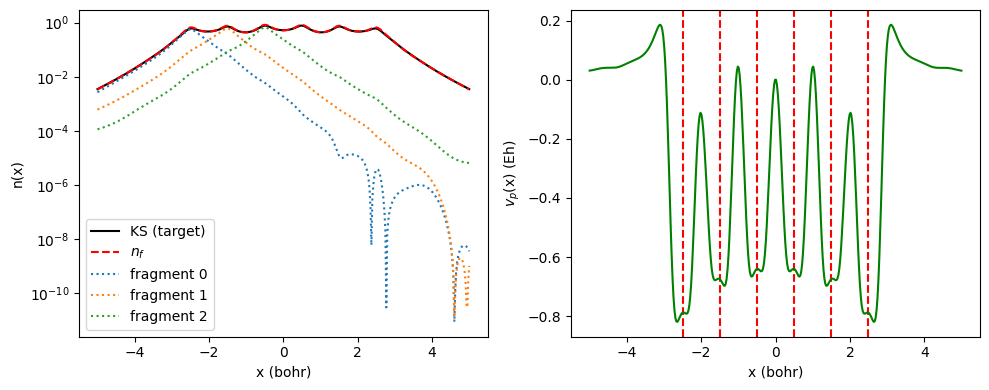

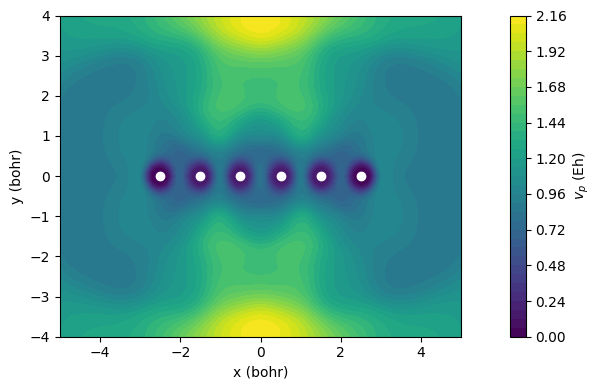

In [5]:
# 1D plot along molecular axis
x = np.linspace(-5, 5, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_i = []
for i in range(3): n_i += [mf1.eval_density(line, frag=i)] # fragment densities
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
for i in range(3): ax[0].semilogy(x, n_i[i], ':', label=f"fragment {i}")
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-5, 5, 200); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()